# Exploración y preprocesamiento de datos

**Proyecto:** Predicción de la gravedad de siniestros viales en CABA

**Autor:** Juan Pablo Monllor - Aprendizaje Automático 2026

Esta notebook carga los datos originales, los explora, documenta las decisiones de limpieza y genera el dataset procesado que se usará para el modelado.

In [58]:
# Librerías para manejar datos (pandas, numpy), hacer gráficos (matplotlib)
# y obtener los feriados nacionales de Argentina (holidays)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import holidays

## 1. Carga de datos

In [26]:
# Cargo el dataset de siniestros viales de CABA (Buenos Aires Data).
# El archivo usa punto y coma como separador, por eso indico sep=";".
# low_memory=False: algunas columnas mezclan números con el texto "SD" (sin dato);
# así pandas lee el archivo completo de una vez y evita el aviso de tipos mezclados.
siniestros = pd.read_csv("../data/raw/siniestros_viales_hechos.csv", sep=";", low_memory=False)

print("Filas y columnas:", siniestros.shape)
siniestros.head()

Filas y columnas: (65818, 21)


,id_siniestro,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro,fecha_siniestro,anio_siniestro,mes_siniestro,dia_siniestro,hora_siniestro,...,direccion_normalizada_siniestro,comuna_siniestro,tipo_de_via_siniestro,geocodificacion_plana,longitud_siniestro,latitud_siniestro,participantes_siniestro,modo_desplazamiento_victima,contraparte_siniestro,gravedad_siniestro
0,LC-2019-0000053,1,1,0,0,2019-01-01,2019,1,1,01:55:00,...,NaN,Comuna 8,AUTOPISTA,POINT (101813.84712503915943671 95578.55507230...,-58.44351,-34.669125,AUTO-UTILITARIO,AUTO,UTILITARIO,LEVE
1,LC-2019-0000647,1,0,1,0,2019-01-01,2019,1,1,18:50:00,...,DE LOS CONSTITUYENTES AV. y HABANA,Comuna 12,AVENIDA,POINT (97510.27137648081406951 105087.83369881...,-58.490436,-34.583403,MOTO-AUTO,MOTO,AUTO,GRAVE
2,LC-2019-0000445,3,3,0,0,2019-01-01,2019,1,1,13:40:00,...,NaN,Comuna 11,NaN,POINT (94371.44237885093025398 102884.19365105...,-58.524662,-34.603255,AUTO-AUTO,AUTO,AUTO,LEVE
3,LC-2019-0000194,1,1,0,0,2019-01-01,2019,1,1,07:15:00,...,NaN,Comuna 9,NaN,POINT (94030.76669932194636203 97681.071761248...,-58.528413,-34.650156,AUTO-CAMION,AUTO,CAMION,LEVE
4,LC-2019-0000329,1,1,0,0,2019-01-01,2019,1,1,12:24:00,...,NaN,Comuna 4,NaN,POINT (105367.86665769023238681 97877.75085908...,-58.404748,-34.648387,AUTO-MOVIL,AUTO,MOVIL,LEVE


In [27]:
# Cargo la lluvia por hora de Open-Meteo.
# Las primeras 3 líneas del archivo no son datos: describen el punto
# (latitud, longitud, altura y zona horaria). Por eso las salteo con skiprows=3.
lluvia = pd.read_csv("../data/external/lluvia_caba_open_meteo_2019_2025.csv", skiprows=3)

print("Filas y columnas:", lluvia.shape)
lluvia.head()

Filas y columnas: (61368, 2)


,time,precipitation (mm)
0,2019-01-01T00:00,0.0
1,2019-01-01T01:00,0.0
2,2019-01-01T02:00,0.0
3,2019-01-01T03:00,0.0
4,2019-01-01T04:00,0.0


## 2. Primera inspección

In [28]:
# info() muestra cada columna con su tipo de dato y cuántos valores no nulos tiene.
# Sirve para saber qué columnas son numéricas, cuáles son texto y dónde hay faltantes.
siniestros.info()

<class 'pandas.DataFrame'>
RangeIndex: 65818 entries, 0 to 65817
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   id_siniestro                      65818 non-null  str  
 1   numero_total_de_victimas          65818 non-null  str  
 2   numero_victimas_leve_siniestro    65818 non-null  int64
 3   numero_victimas_grave_siniestro   65818 non-null  int64
 4   numero_victimas_mortal_siniestro  65818 non-null  int64
 5   fecha_siniestro                   65818 non-null  str  
 6   anio_siniestro                    65818 non-null  int64
 7   mes_siniestro                     65818 non-null  int64
 8   dia_siniestro                     65818 non-null  int64
 9   hora_siniestro                    65741 non-null  str  
 10  rango_horario                     65741 non-null  str  
 11  direccion_normalizada_siniestro   52918 non-null  str  
 12  comuna_siniestro                  62801 non

**Observaciones:** el dataset tiene 65.818 siniestros y 21 columnas (6 numéricas y 15 de texto). La columna `numero_total_de_victimas` aparece como texto porque mezcla números con "SD". Entre las variables que se van a usar como predictoras, `tipo_de_via_siniestro` tiene 12.227 nulos (19%), `comuna_siniestro` 3.017 (5%) y `rango_horario` 77 (0,1%). La decisión sobre estos faltantes se toma en la sección 5.

In [29]:
# Cuento los valores faltantes de dos formas:
# - nulos: celdas vacías (NaN)
# - "SD": el dataset usa el texto "SD" (sin dato) cuando no se registró la información
faltantes = pd.DataFrame({
    "nulos": siniestros.isna().sum(),
    "SD": (siniestros == "SD").sum()
})

# Sumo nulos y "SD" (los dos significan "sin dato") y calculo el porcentaje
# sobre el total de filas del dataset
faltantes["total"] = faltantes["nulos"] + faltantes["SD"]
faltantes["porcentaje"] = (faltantes["total"] / len(siniestros) * 100).round(1)

# Muestro solo las columnas que tienen algún faltante, de mayor a menor
faltantes[faltantes["total"] > 0].sort_values("porcentaje", ascending=False)

,nulos,SD,total,porcentaje
contraparte_siniestro,0,14066,14066,21.4
direccion_normalizada_siniestro,12900,727,13627,20.7
tipo_de_via_siniestro,12227,315,12542,19.1
modo_desplazamiento_victima,0,10928,10928,16.6
comuna_siniestro,3017,535,3552,5.4
numero_total_de_victimas,0,3276,3276,5.0
longitud_siniestro,2378,359,2737,4.2
latitud_siniestro,2378,359,2737,4.2
geocodificacion_plana,2367,7,2374,3.6
hora_siniestro,77,4,81,0.1


**Observaciones:** el dataset registra los datos faltantes de dos formas: celdas vacías (nulos) y el texto "SD" (sin dato). Sumando ambas, las predictoras con más faltantes son la contraparte (21,4%), el tipo de vía (19,1%) y el modo de desplazamiento de la víctima (16,6%); la comuna tiene un 5,4% y el rango horario un 0,1%. Eliminar todas las filas con algún faltante implicaría perder una parte importante de los datos, por lo que su tratamiento se analiza en la sección 5.

In [30]:
# Reviso si hay filas repetidas y si algún siniestro aparece más de una vez.
# Cada fila debería ser un siniestro distinto.
print("Filas duplicadas:", siniestros.duplicated().sum())
print("id_siniestro repetidos:", siniestros["id_siniestro"].duplicated().sum())

Filas duplicadas: 0
id_siniestro repetidos: 0


**Observaciones:** no hay filas duplicadas ni siniestros repetidos: cada fila corresponde a un siniestro distinto (`id_siniestro` único).

In [31]:
# Reviso tipos de dato y nulos en el archivo de lluvia.
lluvia.info()
print()
print("Nulos por columna:")
print(lluvia.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 61368 entries, 0 to 61367
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   time                61368 non-null  str    
 1   precipitation (mm)  61368 non-null  float64
dtypes: float64(1), str(1)
memory usage: 1.9 MB

Nulos por columna:
time                  0
precipitation (mm)    0
dtype: int64


**Observaciones:** el archivo de lluvia tiene 61.368 registros horarios (2019-2025) y no tiene valores nulos. La columna `time` está como texto: se convertirá a fecha y hora en la sección 6, para unirla con los siniestros.

### Unificación de formatos de texto

Antes de explorar las predictoras, unifico la forma en que están escritas algunas categorías. No se elimina ningún registro ni se cambia el significado de los datos: solo se corrige que la misma categoría aparezca escrita de formas distintas.

In [32]:
# 1) Contraparte: hay categorías repetidas en mayúsculas y minúsculas
#    (por ejemplo "AUTO" y "auto"). Paso todo a mayúsculas para que se cuenten juntas.
siniestros["contraparte_siniestro"] = siniestros["contraparte_siniestro"].str.upper()

# 2) Comuna: la misma comuna aparece escrita de tres formas
#    ("Comuna 1", "COMUNA 1" y "1"). Paso a mayúsculas y quito la palabra "COMUNA "
#    para que todas queden solo con el número ("1" a "15"). Los "SD" y los nulos no cambian.
siniestros["comuna_siniestro"] = (
    siniestros["comuna_siniestro"].str.upper().str.replace("COMUNA ", "")
)

# Verifico que quedaron bien
print("Valores distintos en contraparte:", siniestros["contraparte_siniestro"].nunique())
print("Valores distintos en comuna:", siniestros["comuna_siniestro"].nunique())
print(siniestros["comuna_siniestro"].value_counts(dropna=False))

Valores distintos en contraparte: 17
Valores distintos en comuna: 16
comuna_siniestro
1      7241
15     5214
3      4858
4      4562
14     4496
9      4450
7      4368
12     4310
13     3965
10     3776
11     3531
5      3285
8      3088
NaN    3017
6      2772
2      2350
SD      535
Name: count, dtype: int64


## 3. Variable objetivo

In [33]:
# Veo cuántos siniestros hay de cada gravedad (LEVE, GRAVE, MORTAL)
# y qué porcentaje representa cada una sobre el total.
conteo_gravedad = pd.DataFrame({
    "cantidad": siniestros["gravedad_siniestro"].value_counts(),
    "porcentaje": (siniestros["gravedad_siniestro"].value_counts(normalize=True) * 100).round(1)
})
conteo_gravedad

,cantidad,porcentaje
gravedad_siniestro,,
LEVE,62174,94.5
GRAVE,2955,4.5
MORTAL,689,1.0


In [34]:
# Creo la variable objetivo binaria que va a predecir el modelo:
#   0 = leve
#   1 = grave o mortal
# Agrupo GRAVE y MORTAL porque los mortales son muy pocos (1%) para que el modelo
# aprenda a distinguirlos, y porque para priorizar recursos ambos requieren la misma respuesta.
siniestros["grave_o_mortal"] = siniestros["gravedad_siniestro"].isin(["GRAVE", "MORTAL"]).astype(int)

# Verifico cuántos casos quedaron en cada clase
conteo_binaria = pd.DataFrame({
    "cantidad": siniestros["grave_o_mortal"].value_counts(),
    "porcentaje": (siniestros["grave_o_mortal"].value_counts(normalize=True) * 100).round(1)
})
conteo_binaria

,cantidad,porcentaje
grave_o_mortal,,
0,62174,94.5
1,3644,5.5


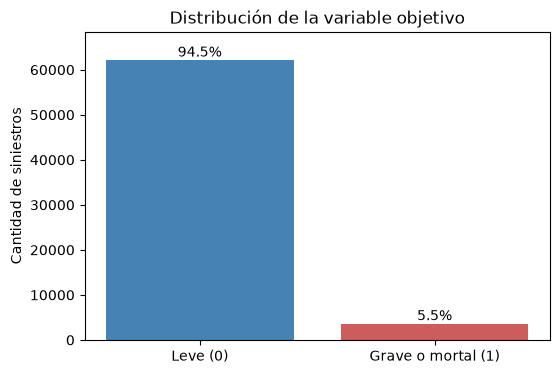

In [35]:
# Gráfico de barras de la variable objetivo para ver el desbalance entre clases.
# Uso las cantidades de la tabla anterior (conteo_binaria).
etiquetas = ["Leve (0)", "Grave o mortal (1)"]
cantidades = [conteo_binaria.loc[0, "cantidad"], conteo_binaria.loc[1, "cantidad"]]

plt.figure(figsize=(6, 4))
barras = plt.bar(etiquetas, cantidades, color=["steelblue", "indianred"])

# Escribo el porcentaje arriba de cada barra
for barra, porcentaje in zip(barras, [conteo_binaria.loc[0, "porcentaje"], conteo_binaria.loc[1, "porcentaje"]]):
    plt.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
             f"{porcentaje}%", ha="center", va="bottom")

# Dejo un 10% de espacio arriba para que el porcentaje no quede pegado al borde
plt.ylim(0, max(cantidades) * 1.1)

plt.title("Distribución de la variable objetivo")
plt.ylabel("Cantidad de siniestros")
plt.show()

**Observaciones:** el 94,5% de los siniestros son leves (62.174) y el 5,5% son graves o mortales (3.644). Dentro de esta última clase, los mortales son solo 689 (1% del total), por lo que se agrupan con los graves. Las clases están muy desbalanceadas: un modelo que prediga siempre "leve" acertaría el 94,5% de las veces sin detectar ningún caso grave. Por eso, en la etapa de modelado, la evaluación se centrará en la clase 1 (recall, precisión y cantidad de falsas alarmas) y no en la exactitud global.

## 4. Exploración de las predictoras

In [36]:
# Tabla de frecuencias del modo de desplazamiento de la víctima (en qué iba la víctima).
# Para cada categoría muestro:
# - cantidad: cuántos siniestros hay
# - porcentaje_graves: qué porcentaje de esos siniestros fue grave o mortal
tabla_modo = siniestros.groupby("modo_desplazamiento_victima").agg(
    cantidad=("grave_o_mortal", "count"),
    porcentaje_graves=("grave_o_mortal", "mean")
)
tabla_modo["porcentaje_graves"] = (tabla_modo["porcentaje_graves"] * 100).round(1)
tabla_modo.sort_values("cantidad", ascending=False)

,cantidad,porcentaje_graves
modo_desplazamiento_victima,,
MOTO,24555,7.5
SD,10928,0.2
PEATON,9415,11.0
BICICLETA,7091,3.9
AUTO,7073,4.2
TRANSPORTE PUBLICO,3633,2.0
TAXI,810,1.1
UTILITARIO,697,4.3
MOVIL,531,1.3


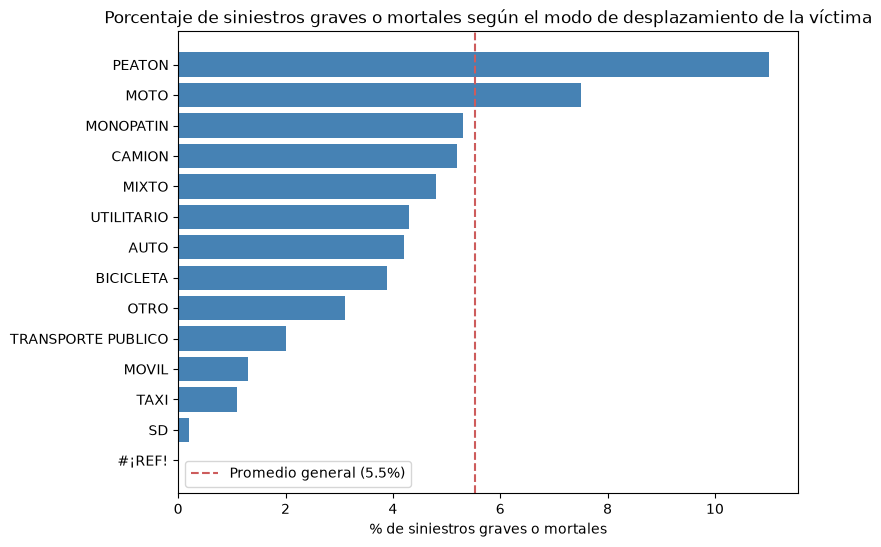

In [37]:
# Gráfico de barras horizontales: porcentaje de siniestros graves o mortales
# según el modo de desplazamiento de la víctima.
# La línea punteada marca el promedio general (5,5%) para comparar cada categoría.
promedio_graves = siniestros["grave_o_mortal"].mean() * 100
datos_grafico = tabla_modo.sort_values("porcentaje_graves")

plt.figure(figsize=(8, 6))
plt.barh(datos_grafico.index, datos_grafico["porcentaje_graves"], color="steelblue")
plt.axvline(promedio_graves, color="indianred", linestyle="--",
            label=f"Promedio general ({promedio_graves:.1f}%)")

plt.title("Porcentaje de siniestros graves o mortales según el modo de desplazamiento de la víctima")
plt.xlabel("% de siniestros graves o mortales")
plt.legend()
plt.show()

**Observaciones:** el modo de desplazamiento de la víctima muestra diferencias claras. Los peatones (11,0%) y los motociclistas (7,5%) tienen un porcentaje de siniestros graves o mortales muy superior al promedio general (5,5%), mientras que las víctimas que viajaban en transporte público (2,0%), taxi (1,1%) o móviles (1,3%) tienen porcentajes mucho menores. Una posible explicación es que peatones y motociclistas están menos protegidos ante un impacto, aunque los datos no permiten confirmarlo.

Los registros sin dato ("SD", 10.928 casos) tienen solo un 0,2% de siniestros graves o mortales. Esto sugiere que los casos graves quedan mejor registrados que los leves, por lo que la categoría "SD" no representa un tipo de vehículo sino una diferencia en cómo se completa el registro. Se analiza en la sección 5. Además, hay 1 registro con el valor "#¡REF!", un error de carga que se corrige en la sección 7.

In [40]:
# Tabla de frecuencias de la contraparte (el otro participante del siniestro).
# Para cada categoría muestro:
# - cantidad: cuántos siniestros hay
# - porcentaje_graves: qué porcentaje de esos siniestros fue grave o mortal
tabla_contraparte = siniestros.groupby("contraparte_siniestro").agg(
    cantidad=("grave_o_mortal", "count"),
    porcentaje_graves=("grave_o_mortal", "mean")
)
tabla_contraparte["porcentaje_graves"] = (tabla_contraparte["porcentaje_graves"] * 100).round(1)
tabla_contraparte.sort_values("cantidad", ascending=False)

,cantidad,porcentaje_graves
contraparte_siniestro,,
AUTO,29996,5.9
SD,14066,0.9
TRANSPORTE PUBLICO,6035,7.9
UTILITARIO,3575,4.6
MOTO,3496,9.1
TAXI,2624,2.7
CAMION,2579,10.2
OBJETO FIJO,1521,22.0
MOVIL,804,4.1


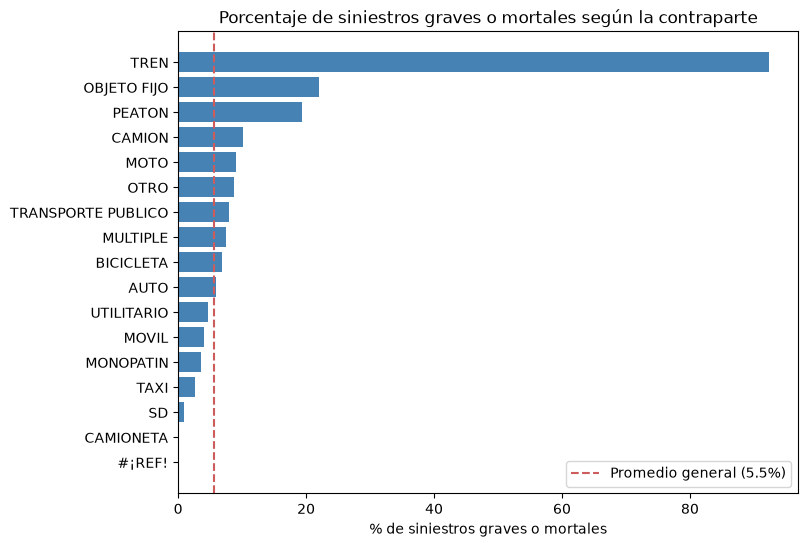

In [41]:
# Gráfico de barras horizontales: porcentaje de siniestros graves o mortales
# según la contraparte (el otro participante del siniestro).
# La línea punteada marca el promedio general para comparar cada categoría.
datos_grafico = tabla_contraparte.sort_values("porcentaje_graves")

plt.figure(figsize=(8, 6))
plt.barh(datos_grafico.index, datos_grafico["porcentaje_graves"], color="steelblue")
plt.axvline(promedio_graves, color="indianred", linestyle="--",
            label=f"Promedio general ({promedio_graves:.1f}%)")

plt.title("Porcentaje de siniestros graves o mortales según la contraparte")
plt.xlabel("% de siniestros graves o mortales")
plt.legend()
plt.show()

**Observaciones:** la contraparte es la variable que muestra las diferencias más marcadas. Los choques contra un objeto fijo (poste, árbol, columna) tienen un 22,0% de siniestros graves o mortales, cuatro veces el promedio general (5,5%). También superan el promedio los atropellos a peatones como contraparte (19,4%), los choques con camiones (10,2%), con motos (9,1%) y con transporte público (7,9%). En cambio, los choques con taxis (2,7%) están muy por debajo.

Los siniestros con un tren tienen un 92,3% de casos graves o mortales. Una posible explicación es que el tren, por su peso y su tamaño, no puede frenar a tiempo, por lo que un impacto suele tener consecuencias graves (algo similar a lo que ocurre con los accidentes aéreos: poco frecuentes, pero muy graves cuando suceden). Sin embargo, son solo 13 casos, por lo que ese porcentaje es poco confiable y la hipótesis no puede confirmarse con estos datos.

Como en el modo de desplazamiento, los registros sin dato ("SD", 14.066 casos) tienen muy pocos casos graves (0,9%), lo que se analiza en la sección 5. La categoría "CAMIONETA" (74 casos) corresponde a vehículos que la metodología del dataset incluye dentro de "UTILITARIO", y el registro "#¡REF!" es un error de carga; ambos se corrigen en la sección 7.

In [42]:
# Tabla de frecuencias del tipo de vía donde ocurrió el siniestro.
# Para cada categoría muestro:
# - cantidad: cuántos siniestros hay
# - porcentaje_graves: qué porcentaje de esos siniestros fue grave o mortal
# dropna=False: incluyo también los nulos (tipo de vía sin registrar) para ver cómo se comportan
tabla_via = siniestros.groupby("tipo_de_via_siniestro", dropna=False).agg(
    cantidad=("grave_o_mortal", "count"),
    porcentaje_graves=("grave_o_mortal", "mean")
)
tabla_via["porcentaje_graves"] = (tabla_via["porcentaje_graves"] * 100).round(1)
tabla_via.sort_values("cantidad", ascending=False)

,cantidad,porcentaje_graves
tipo_de_via_siniestro,,
AVENIDA,30525,6.0
CALLE,18794,4.3
NaN,12227,5.0
AV. GRAL. PAZ,2916,6.8
AUTOPISTA,1041,13.1
SD,315,14.3


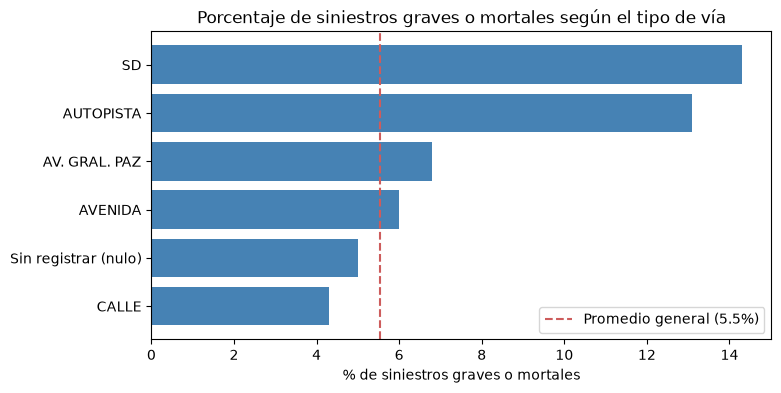

In [43]:
# Gráfico de barras horizontales: porcentaje de siniestros graves o mortales
# según el tipo de vía. Renombro los nulos (NaN) como "Sin registrar (nulo)"
# para poder mostrarlos en el gráfico, ya que las etiquetas deben ser texto.
datos_grafico = tabla_via.sort_values("porcentaje_graves")
etiquetas_via = datos_grafico.index.fillna("Sin registrar (nulo)")

plt.figure(figsize=(8, 4))
plt.barh(etiquetas_via, datos_grafico["porcentaje_graves"], color="steelblue")
plt.axvline(promedio_graves, color="indianred", linestyle="--",
            label=f"Promedio general ({promedio_graves:.1f}%)")

plt.title("Porcentaje de siniestros graves o mortales según el tipo de vía")
plt.xlabel("% de siniestros graves o mortales")
plt.legend()
plt.show()

**Observaciones:** el tipo de vía muestra que los siniestros en autopistas tienen un 13,1% de casos graves o mortales, más del doble del promedio general (5,5%). Les siguen la Av. General Paz (6,8%) y las avenidas (6,0%), mientras que en las calles el porcentaje es menor (4,3%). Una posible explicación es la mayor velocidad de circulación en autopistas y avenidas, aunque el dataset no registra la velocidad y no permite confirmarlo.

A diferencia de lo observado en el modo de desplazamiento y en la contraparte, los faltantes del tipo de vía no se concentran en los casos leves: los nulos (12.227) tienen un porcentaje de graves similar al promedio (5,0%) y los "SD" (315) uno mayor (14,3%). Por lo tanto, los registros sin dato no se comportan igual en todas las columnas, y su tratamiento se decide por separado en la sección 5.

In [44]:
# Tabla de frecuencias de la comuna donde ocurrió el siniestro.
# Para cada categoría muestro:
# - cantidad: cuántos siniestros hay
# - porcentaje_graves: qué porcentaje de esos siniestros fue grave o mortal
# dropna=False: incluyo los nulos (comuna sin registrar) para ver cómo se comportan
tabla_comuna = siniestros.groupby("comuna_siniestro", dropna=False).agg(
    cantidad=("grave_o_mortal", "count"),
    porcentaje_graves=("grave_o_mortal", "mean")
)
tabla_comuna["porcentaje_graves"] = (tabla_comuna["porcentaje_graves"] * 100).round(1)
tabla_comuna.sort_values("porcentaje_graves", ascending=False)

,cantidad,porcentaje_graves
comuna_siniestro,,
NaN,3017,17.3
SD,535,13.3
13,3965,5.9
12,4310,5.8
14,4496,5.8
4,4562,5.8
8,3088,5.6
11,3531,5.3
2,2350,5.0


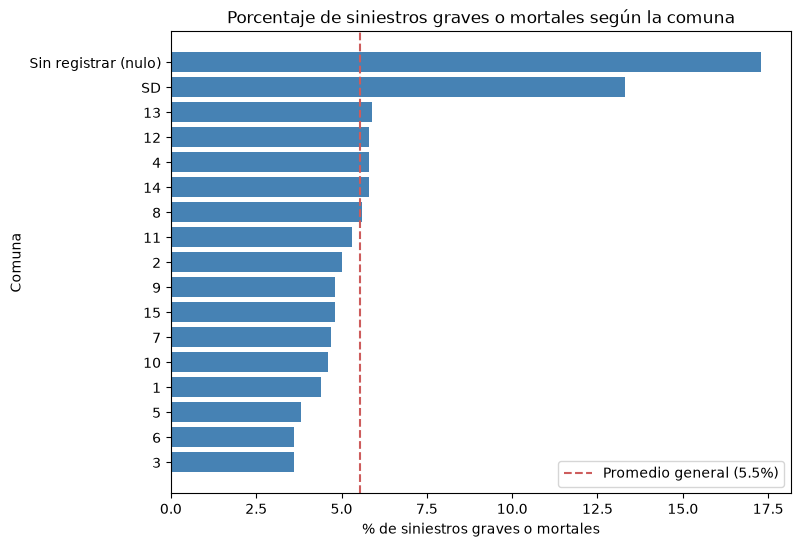

In [45]:
# Gráfico de barras horizontales: porcentaje de siniestros graves o mortales
# según la comuna. Renombro los nulos (NaN) como "Sin registrar (nulo)"
# para poder mostrarlos en el gráfico, ya que las etiquetas deben ser texto.
datos_grafico = tabla_comuna.sort_values("porcentaje_graves")
etiquetas_comuna = datos_grafico.index.fillna("Sin registrar (nulo)")

plt.figure(figsize=(8, 6))
plt.barh(etiquetas_comuna, datos_grafico["porcentaje_graves"], color="steelblue")
plt.axvline(promedio_graves, color="indianred", linestyle="--",
            label=f"Promedio general ({promedio_graves:.1f}%)")

plt.title("Porcentaje de siniestros graves o mortales según la comuna")
plt.xlabel("% de siniestros graves o mortales")
plt.ylabel("Comuna")
plt.legend()
plt.show()

**Observaciones:** las 15 comunas tienen porcentajes de siniestros graves o mortales parecidos, entre 3,6% (comunas 3 y 6) y 5,9% (comuna 13). Las diferencias son menores que en el modo de desplazamiento o la contraparte, por lo que la comuna parece aportar menos información para anticipar la gravedad.

En cambio, los siniestros sin comuna registrada tienen porcentajes mucho más altos: 17,3% en los nulos (3.017) y 13,3% en los "SD" (535). En esos registros también suele faltar el tipo de vía, lo que indica que no se pudo determinar con precisión el lugar del hecho. Según las notas metodológicas, los casos graves y mortales se completan con información de otras fuentes (SAME, hospitales, fiscalías), por lo que una posible explicación es que esos registros lleguen con una ubicación menos precisa. Se analiza en la sección 5.

Referencia: las comunas se identifican con un número del 1 al 15 y agrupan los 48 barrios de la Ciudad (por ejemplo, la comuna 1 incluye Retiro, San Nicolás y Puerto Madero, y la comuna 14 corresponde a Palermo). El detalle completo se incluye en el diccionario de datos.

In [48]:
# La hora del siniestro (rango_horario) está guardada como texto ("0" a "23").
# La paso a número para poder ordenarla de 0 a 23. Los "SD" y los nulos quedan
# como faltantes (errors="coerce"); son solo 81 registros (0,1%).
hora = pd.to_numeric(siniestros["rango_horario"], errors="coerce")

# Para cada hora del día calculo cuántos siniestros hay y qué porcentaje fue grave o mortal
tabla_hora = siniestros.groupby(hora).agg(
    cantidad=("grave_o_mortal", "count"),
    porcentaje_graves=("grave_o_mortal", "mean")
)
tabla_hora["porcentaje_graves"] = (tabla_hora["porcentaje_graves"] * 100).round(1)

# Muestro las horas como enteros (0, 1, 2...) en lugar de decimales (0.0, 1.0...)
tabla_hora.index = tabla_hora.index.astype(int)
tabla_hora

,cantidad,porcentaje_graves
rango_horario,,
0,1901,10.9
1,947,7.4
2,693,9.7
3,508,15.7
4,454,14.3
5,754,11.4
6,1317,9.7
7,2150,6.8
8,2960,4.4


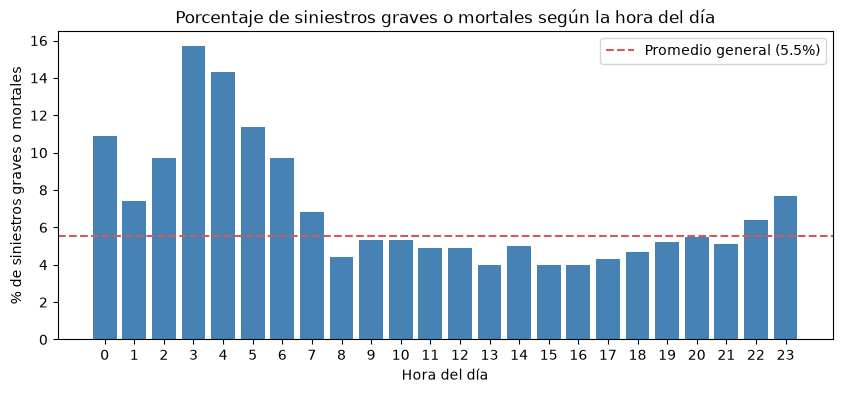

In [49]:
# Gráfico de barras: porcentaje de siniestros graves o mortales según la hora del día.
# La línea punteada marca el promedio general.
plt.figure(figsize=(10, 4))
plt.bar(tabla_hora.index, tabla_hora["porcentaje_graves"], color="steelblue")
plt.axhline(promedio_graves, color="indianred", linestyle="--",
            label=f"Promedio general ({promedio_graves:.1f}%)")

plt.title("Porcentaje de siniestros graves o mortales según la hora del día")
plt.xlabel("Hora del día")
plt.ylabel("% de siniestros graves o mortales")
plt.xticks(range(0, 24))
plt.legend()
plt.show()

**Observaciones:** la hora del día muestra un patrón claro. Entre las 0 y las 6 hay menos siniestros, pero un porcentaje mucho mayor de casos graves o mortales: entre 7,4% y 15,7%, con un pico a las 3 de la mañana. Durante el día (de 8 a 18) ocurre la mayor cantidad de siniestros, pero con porcentajes de graves por debajo del promedio (entre 4,0% y 5,3%). A partir de las 22 el porcentaje vuelve a subir. Algunas posibles explicaciones son la mayor velocidad de circulación por el menor tránsito, la menor visibilidad o el cansancio, aunque el dataset no registra esa información y no permite confirmarlas.

## 5. Análisis de los registros sin dato

En la sección 4 se observó que los faltantes (nulos y "SD") no se comportan igual en todas las predictoras: en algunas se concentran en los siniestros leves y en otras en los graves. Esto puede reflejar diferencias en cómo se investigan y completan los registros según la gravedad del hecho. Si el modelo aprendiera a usar la ausencia de un dato como pista, estaría dependiendo de cómo se completó el registro y no de las circunstancias del siniestro. En esta sección se compara, para cada predictora, el porcentaje de siniestros graves cuando el dato falta y cuando está presente.

In [50]:
# Para cada predictora comparo el porcentaje de siniestros graves o mortales
# cuando el dato falta (nulo o "SD") y cuando está presente.
# Si los porcentajes son muy distintos, la ausencia del dato está relacionada
# con la gravedad y el modelo podría usarla como pista.
predictoras = ["modo_desplazamiento_victima", "contraparte_siniestro",
               "tipo_de_via_siniestro", "comuna_siniestro", "rango_horario"]

filas = []
for columna in predictoras:
    falta = siniestros[columna].isna() | (siniestros[columna] == "SD")
    filas.append({
        "predictora": columna,
        "faltantes": falta.sum(),
        "porcentaje_faltantes": round(falta.mean() * 100, 1),
        "graves_si_falta": round(siniestros.loc[falta, "grave_o_mortal"].mean() * 100, 1),
        "graves_si_esta": round(siniestros.loc[~falta, "grave_o_mortal"].mean() * 100, 1)
    })

pd.DataFrame(filas)

,predictora,faltantes,porcentaje_faltantes,graves_si_falta,graves_si_esta
0,modo_desplazamiento_victima,10928,16.6,0.2,6.6
1,contraparte_siniestro,14066,21.4,0.9,6.8
2,tipo_de_via_siniestro,12542,19.1,5.2,5.6
3,comuna_siniestro,3552,5.4,16.7,4.9
4,rango_horario,81,0.1,35.8,5.5


**Observaciones:**

- En `modo_desplazamiento_victima` y `contraparte_siniestro`, cuando el dato falta el porcentaje de graves es casi nulo (0,2% y 0,9%), frente a 6,6% y 6,8% cuando está presente. Una hipótesis es que en los siniestros leves el registro se completa con menos detalle. Si se dejaran estos faltantes, el modelo podría aprender que "SD" significa "leve", y eso dependería de cómo se cargó el dato y no de cómo ocurrió el siniestro.
- En `tipo_de_via_siniestro` los porcentajes son muy parecidos (5,2% y 5,6%), por lo que la falta del dato no parece relacionada con la gravedad.
- En `comuna_siniestro` y `rango_horario` ocurre lo contrario: cuando el dato falta, el porcentaje de graves es mayor (16,7% y 35,8%). En el caso de la hora son solo 81 registros (0,1%).

In [51]:
# Mido cuánto se perdería si se eliminan las filas con el dato faltante
# en el vehículo de la víctima o en la contraparte.
falta_modo = (siniestros["modo_desplazamiento_victima"].isna() |
              (siniestros["modo_desplazamiento_victima"] == "SD"))
falta_contraparte = (siniestros["contraparte_siniestro"].isna() |
                     (siniestros["contraparte_siniestro"] == "SD"))
falta_alguno = falta_modo | falta_contraparte

total_graves = siniestros["grave_o_mortal"].sum()
graves_perdidos = siniestros.loc[falta_alguno, "grave_o_mortal"].sum()
quedan = siniestros.loc[~falta_alguno]

print("Filas con dato faltante en vehículo o contraparte:", falta_alguno.sum(),
      f"({round(falta_alguno.mean() * 100, 1)}% del total)")
print("Siniestros graves en esas filas:", graves_perdidos,
      f"({round(graves_perdidos / total_graves * 100, 1)}% de los graves)")
print("Filas que quedarían:", len(quedan))
print("Porcentaje de graves en lo que queda:",
      round(quedan["grave_o_mortal"].mean() * 100, 1), "%")

Filas con dato faltante en vehículo o contraparte: 14646 (22.3% del total)
Siniestros graves en esas filas: 134 (3.7% de los graves)
Filas que quedarían: 51172
Porcentaje de graves en lo que queda: 6.9 %


**Observaciones:**

- 14.646 registros (22,3%) tienen el dato faltante en el vehículo de la víctima o en la contraparte, pero entre ellos hay solo 134 siniestros graves (3,7% del total de graves).
- Si se eliminan, quedan 51.172 registros y el porcentaje de graves pasa de 5,5% a 6,9%. Se pierde una parte importante de los leves, pero casi ninguno de los casos que se busca predecir.

### Decisiones sobre los registros sin dato

A partir de este análisis se toman las siguientes decisiones, que se aplican en la sección 7:

1. **Vehículo de la víctima y contraparte:** se eliminan los registros con dato faltante (14.646 filas, 22,3%), porque la ausencia del dato está asociada a los siniestros leves y el modelo podría usarla como pista.
2. **Tipo de vía:** los faltantes (nulos y "SD") se agrupan en una categoría "SIN DATO", ya que el porcentaje de graves es similar con y sin el dato.
3. **Comuna:** no se usa como predictora. En la sección 4 mostró poca diferencia entre comunas, y sus faltantes se concentran en los siniestros graves, lo que sugiere que dependen de cómo se completa el registro y no de dónde ocurre el siniestro.
4. **Hora:** se eliminan los registros sin hora, por ser muy pocos (0,1%).

## 6. Variables nuevas

Se agregan tres variables que no están en el dataset original y que se conocen al momento del aviso del siniestro:

- **Lluvia:** milímetros de precipitación en la hora del siniestro, tomados de Open-Meteo. Es un único punto para toda la Ciudad, por lo que se usa como aproximación de las condiciones del momento.
- **Tipo de día:** hábil, fin de semana o feriado.
- **Estación del año.**

### Preparación de las fechas

Para unir ambos archivos, primero se convierten las fechas de texto a formato fecha.

In [52]:
# Convierto las fechas de texto a formato fecha para poder unir ambos archivos.
siniestros["fecha_siniestro"] = pd.to_datetime(siniestros["fecha_siniestro"], format="%Y-%m-%d")

lluvia["time"] = pd.to_datetime(lluvia["time"])
lluvia = lluvia.rename(columns={"time": "fecha_hora", "precipitation (mm)": "lluvia_mm"})

print("Siniestros:", siniestros["fecha_siniestro"].min(), "a", siniestros["fecha_siniestro"].max())
print("Lluvia:", lluvia["fecha_hora"].min(), "a", lluvia["fecha_hora"].max())
lluvia.head()

Siniestros: 2019-01-01 00:00:00 a 2025-12-31 00:00:00
Lluvia: 2019-01-01 00:00:00 a 2025-12-31 23:00:00


,fecha_hora,lluvia_mm
0,2019-01-01 00:00:00,0.0
1,2019-01-01 01:00:00,0.0
2,2019-01-01 02:00:00,0.0
3,2019-01-01 03:00:00,0.0
4,2019-01-01 04:00:00,0.0


### Lluvia en la hora del siniestro

Se arma una columna con la fecha y la hora del siniestro, usando `rango_horario`, y se une con los datos de lluvia por esa columna. No se usan minutos ni segundos: alcanza con la hora para describir las condiciones del momento.

In [53]:
# Armo la fecha y hora del siniestro sumando la hora (rango_horario) a la fecha.
# Las filas sin hora quedan vacías (se eliminan en la sección 7).
hora = pd.to_numeric(siniestros["rango_horario"], errors="coerce")
siniestros["fecha_hora"] = siniestros["fecha_siniestro"] + pd.to_timedelta(hora, unit="h")

# Uno con la lluvia por fecha y hora. "left" conserva todos los siniestros.
siniestros = siniestros.merge(lluvia, on="fecha_hora", how="left")

print("Filas después de unir:", len(siniestros))
print("Siniestros sin dato de lluvia:", siniestros["lluvia_mm"].isna().sum())
siniestros[["fecha_siniestro", "rango_horario", "fecha_hora", "lluvia_mm"]].head()

Filas después de unir: 65818
Siniestros sin dato de lluvia: 81


,fecha_siniestro,rango_horario,fecha_hora,lluvia_mm
0,2019-01-01,1,2019-01-01 01:00:00,0.0
1,2019-01-01,18,2019-01-01 18:00:00,0.1
2,2019-01-01,13,2019-01-01 13:00:00,0.0
3,2019-01-01,7,2019-01-01 07:00:00,0.0
4,2019-01-01,12,2019-01-01 12:00:00,0.0


**Observaciones:**

- La unión conserva los 65.818 registros, es decir que no se duplicaron filas.
- Los 81 siniestros sin dato de lluvia son los que no tienen hora registrada, que se eliminan en la sección 7.

In [54]:
# Comparo el porcentaje de graves cuando llovía y cuando no, en la hora del siniestro.
llovia = np.where(siniestros["lluvia_mm"] > 0, "Con lluvia", "Sin lluvia")

tabla_lluvia = (siniestros[siniestros["lluvia_mm"].notna()]
                .groupby(llovia[siniestros["lluvia_mm"].notna()])
                .agg(cantidad=("grave_o_mortal", "count"),
                     porcentaje_graves=("grave_o_mortal", "mean")))
tabla_lluvia["porcentaje_graves"] = (tabla_lluvia["porcentaje_graves"] * 100).round(1)
tabla_lluvia

,cantidad,porcentaje_graves
Con lluvia,6312,5.6
Sin lluvia,59425,5.5


**Observaciones:**

- El porcentaje de graves es prácticamente igual con lluvia (5,6%) y sin lluvia (5,5%). Por sí sola, la lluvia en la hora del siniestro no muestra relación con la gravedad.
- Una hipótesis es que la lluvia influya más en la cantidad de siniestros que en su gravedad, o que el dato de un único punto para toda la Ciudad no refleje bien las condiciones de cada lugar.
- Se conserva la variable para evaluar en la Entrega 3 si aporta combinada con otras predictoras.

### Tipo de día

Se clasifica cada siniestro según el día en que ocurrió: hábil, fin de semana o feriado. Los feriados nacionales se obtienen de la librería `holidays`.

In [59]:
# Clasifico cada fecha como feriado, fin de semana o día hábil.
feriados = holidays.Argentina(years=range(2019, 2026))

def tipo_de_dia(fecha):
    if fecha in feriados:
        return "FERIADO"
    elif fecha.dayofweek >= 5:   # 5 = sábado, 6 = domingo
        return "FIN DE SEMANA"
    else:
        return "HABIL"

siniestros["tipo_dia"] = siniestros["fecha_siniestro"].apply(tipo_de_dia)

tabla_dia = siniestros.groupby("tipo_dia").agg(
    cantidad=("grave_o_mortal", "count"),
    porcentaje_graves=("grave_o_mortal", "mean"))
tabla_dia["porcentaje_graves"] = (tabla_dia["porcentaje_graves"] * 100).round(1)
tabla_dia

,cantidad,porcentaje_graves
tipo_dia,,
FERIADO,2300,7.3
FIN DE SEMANA,13119,6.8
HABIL,50399,5.1


**Observaciones:**

- El porcentaje de graves es mayor en feriados (7,3%) y fines de semana (6,8%) que en días hábiles (5,1%).
- Una hipótesis es que esos días haya menos tránsito y se circule a mayor velocidad, o más salidas nocturnas. Puede estar relacionado con lo observado en la hora: la madrugada concentra más siniestros graves y es más frecuente en fines de semana y feriados.
- Los feriados son el grupo más chico (2.300 registros), por lo que su porcentaje es menos estable que el de los otros dos.

### Estación del año

Se asigna la estación según el mes del siniestro, con las estaciones del hemisferio sur: verano (diciembre a febrero), otoño (marzo a mayo), invierno (junio a agosto) y primavera (septiembre a noviembre). Es una aproximación por mes, ya que los cambios de estación no coinciden exactamente con el inicio de cada mes.

In [60]:
# Asigno la estación según el mes de la fecha del siniestro (hemisferio sur).
estaciones = {12: "VERANO", 1: "VERANO", 2: "VERANO",
              3: "OTOÑO", 4: "OTOÑO", 5: "OTOÑO",
              6: "INVIERNO", 7: "INVIERNO", 8: "INVIERNO",
              9: "PRIMAVERA", 10: "PRIMAVERA", 11: "PRIMAVERA"}

siniestros["estacion"] = siniestros["fecha_siniestro"].dt.month.map(estaciones)

tabla_estacion = siniestros.groupby("estacion").agg(
    cantidad=("grave_o_mortal", "count"),
    porcentaje_graves=("grave_o_mortal", "mean"))
tabla_estacion["porcentaje_graves"] = (tabla_estacion["porcentaje_graves"] * 100).round(1)
tabla_estacion

,cantidad,porcentaje_graves
estacion,,
INVIERNO,16687,5.7
OTOÑO,16240,5.5
PRIMAVERA,17565,5.2
VERANO,15326,5.7


**Observaciones:**

- Los siniestros se reparten de forma pareja entre las estaciones (entre 15.300 y 17.600 registros cada una).
- El porcentaje de graves varía poco: entre 5,2% en primavera y 5,7% en invierno y verano, cerca del promedio general de 5,5%. Por sí sola, la estación no muestra una relación clara con la gravedad.
- Al igual que la lluvia, se conserva para evaluar en la Entrega 3 si aporta combinada con otras predictoras.

### Resumen de las variables nuevas

| Variable | Origen | Relación observada con la gravedad |
|---|---|---|
| `lluvia_mm` | Open-Meteo, unida por fecha y hora | Sin diferencia (5,6% con lluvia y 5,5% sin lluvia) |
| `tipo_dia` | Fecha del siniestro y librería `holidays` | Mayor en feriados (7,3%) y fines de semana (6,8%) que en días hábiles (5,1%) |
| `estacion` | Mes de la fecha del siniestro | Diferencias pequeñas (entre 5,2% y 5,7%) |